In [105]:
# === B1 ===
import os
ROOT = "/content/simuteh-2330511083"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
%cd {ROOT}

/content/simuteh-2330511083


In [106]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
"""
import os
import csv
import cv2
import numpy as np

SEED = 1083          # 4 digit terakhir NIM 2330511083
N_PER_KELAS = 20
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")
rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])  # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]  # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)  # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun  # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)  # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)  # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])  # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()

Overwriting src/buat_dataset_sintetis.py


In [107]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}

Overwriting src/utils_cv.py


In [108]:
!python src/buat_dataset_sintetis.py
!ls data/sintetis/citra | wc -l

Selesai: 60 citra tersimpan di data/sintetis
60


In [109]:
%cd /content/simuteh-2330511083/notebook

/content/simuteh-2330511083/notebook


OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 247
piksel (y=100, x=200) dalam urutan BGR: [168 202 192]


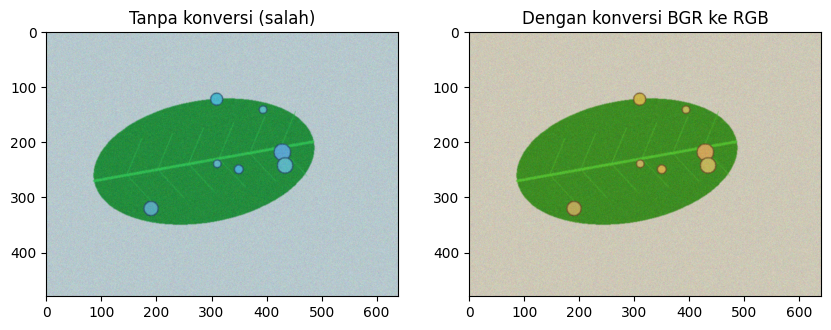

In [110]:
import sys
sys.path.append("../src")

import cv2
import numpy as np
import skimage
import matplotlib.pyplot as plt
from utils_cv import baca

print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.savefig("../hasil/b1_bgr_rgb.png"); plt.show()

In [111]:
!pip list 2>/dev/null | grep -i opencv
import cv2; print("cv2 yang aktif:", cv2.__version__)

opencv-contrib-python                 4.14.0.94
opencv-python                         5.0.0.93
opencv-python-headless                5.0.0.93
cv2 yang aktif: 4.14.0


In [112]:
%%writefile /content/simuteh-2330511083/requirements.txt
opencv-contrib-python==4.14.0.94
numpy==2.1.3
matplotlib==3.10.0
scikit-image==0.25.2
pandas==2.2.3
pillow==11.3.0

Overwriting /content/simuteh-2330511083/requirements.txt


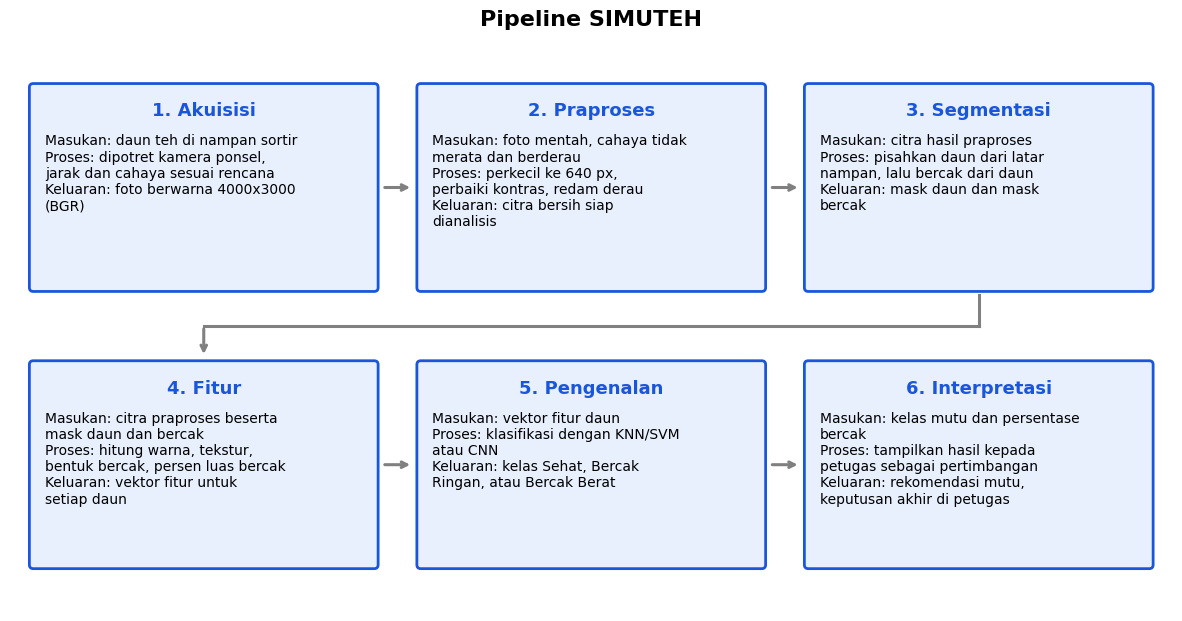

In [115]:
import textwrap
from matplotlib.patches import FancyBboxPatch

tahap = [
    ("1. Akuisisi",
     "Masukan: daun teh di nampan sortir",
     "Proses: dipotret kamera ponsel, jarak dan cahaya sesuai rencana",
     "Keluaran: foto berwarna 4000x3000 (BGR)"),
    ("2. Praproses",
     "Masukan: foto mentah, cahaya tidak merata dan berderau",
     "Proses: perkecil ke 640 px, perbaiki kontras, redam derau",
     "Keluaran: citra bersih siap dianalisis"),
    ("3. Segmentasi",
     "Masukan: citra hasil praproses",
     "Proses: pisahkan daun dari latar nampan, lalu bercak dari daun",
     "Keluaran: mask daun dan mask bercak"),
    ("4. Fitur",
     "Masukan: citra praproses beserta mask daun dan bercak",
     "Proses: hitung warna, tekstur, bentuk bercak, persen luas bercak",
     "Keluaran: vektor fitur untuk setiap daun"),
    ("5. Pengenalan",
     "Masukan: vektor fitur daun",
     "Proses: klasifikasi dengan KNN/SVM atau CNN",
     "Keluaran: kelas Sehat, Bercak Ringan, atau Bercak Berat"),
    ("6. Interpretasi",
     "Masukan: kelas mutu dan persentase bercak",
     "Proses: tampilkan hasil kepada petugas sebagai pertimbangan",
     "Keluaran: rekomendasi mutu, keputusan akhir di petugas"),
]

LB, TG = 4.4, 2.6
pos = [(0.3, 4.2), (5.3, 4.2), (10.3, 4.2),
       (0.3, 0.6), (5.3, 0.6), (10.3, 0.6)]

fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set_xlim(0, 15); ax.set_ylim(0, 7.5); ax.axis("off")
ax.set_title("Pipeline SIMUTEH", fontsize=16, fontweight="bold")

for (judul, m, p, k), (x, y) in zip(tahap, pos):
    ax.add_patch(FancyBboxPatch((x, y), LB, TG, boxstyle="round,pad=0.05",
                                fc="#e8f0fe", ec="#1a56db", lw=2))
    ax.text(x + LB/2, y + TG - 0.3, judul, ha="center", va="center",
            fontsize=13, fontweight="bold", color="#1a56db")
    isi = "\n".join(textwrap.fill(t, 34) for t in (m, p, k))
    ax.text(x + 0.15, y + TG - 0.6, isi, ha="left", va="top", fontsize=10)

def panah(a, b):
    ax.annotate("", xy=b, xytext=a,
                arrowprops=dict(arrowstyle="->", lw=2.2, color="gray"))

panah((0.3 + LB + 0.1, 5.5), (5.3 - 0.1, 5.5))
panah((5.3 + LB + 0.1, 5.5), (10.3 - 0.1, 5.5))
ax.plot([12.5, 12.5], [4.1, 3.7], color="gray", lw=2.2)
ax.plot([12.5, 2.5], [3.7, 3.7], color="gray", lw=2.2)
panah((2.5, 3.7), (2.5, 3.3))
panah((0.3 + LB + 0.1, 1.9), (5.3 - 0.1, 1.9))
panah((5.3 + LB + 0.1, 1.9), (10.3 - 0.1, 1.9))

plt.savefig("../hasil/b1_pipeline.png", dpi=150, bbox_inches="tight")
plt.show()